# 01 · Data Cleaning and Preprocessing
**Project:** Retail Shop Analysis Using Data Analytics

**Goal of this notebook:** turn the raw retail transaction file into a clean, validated,
analysis-ready dataset (`dataset/cleaned_data.csv`) and record every step taken.

**Dataset:** *Superstore Sales* (Canadian edition), a public sample retail dataset first
published by Tableau Software as a teaching dataset, and widely mirrored on Kaggle and GitHub.
Copy used: `https://raw.githubusercontent.com/curran/data/gh-pages/superstoreSales/superstoreSales.csv`

| Step | What we do |
|---|---|
| 1 | Load the raw file with the correct encoding |
| 2 | Inspect structure, data types and quality |
| 3 | Standardise column names and text |
| 4 | Convert data types (dates, integers) |
| 5 | Remove empty and duplicate records |
| 6 | Handle missing values |
| 7 | Validate numerical values and business rules |
| 8 | Detect and handle outliers |
| 9 | Create calculated (derived) columns |
| 10 | Save the cleaned data and the cleaning log |

In [1]:
# Import libraries
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import viz_style as vs

vs.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

RAW_PATH = "../dataset/raw_data.csv"
CLEAN_PATH = "../dataset/cleaned_data.csv"
cleaning_log = []          # every step appends a note here -> saved to results/

def log(step, detail, rows_before=None, rows_after=None):
    """Record a preprocessing step so it can be documented in the report."""
    cleaning_log.append({"step": step, "detail": detail,
                         "rows_before": rows_before, "rows_after": rows_after})
    print(f"[{step}] {detail}")

## Step 1 · Load the raw data
The raw file was exported on an old Mac system, so it has two unusual properties:
* line endings are a carriage return (`\r`) instead of a newline, and
* text is in the **Mac Roman** encoding (symbols like ® and ™ in product names).

Reading it with the default settings would merge all rows into one line or garble the
symbols, so we tell pandas exactly how the file is encoded.

In [2]:
raw = pd.read_csv(RAW_PATH, lineterminator="\r", encoding="mac_roman")
print("Raw shape (rows, columns):", raw.shape)
log("Load", f"Loaded raw file with {raw.shape[0]} rows and {raw.shape[1]} columns "
    "(Mac Roman encoding, CR line endings).", None, raw.shape[0])
raw.head()

Raw shape (rows, columns): (8400, 21)
[Load] Loaded raw file with 8400 rows and 21 columns (Mac Roman encoding, CR line endings).


,Row ID,Order ID,Order Date,Order Priority,Order Quantity,Sales,Discount,Ship Mode,Profit,Unit Price,Shipping Cost,Customer Name,Province,Region,Customer Segment,Product Category,Product Sub-Category,Product Name,Product Container,Product Base Margin,Ship Date
0,1,3.0,10/13/2010,Low,6.0,261.5400,0.04,Regular Air,-213.25,38.94,35.00,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,10/20/2010
1,49,293.0,10/1/2012,High,49.0,10123.0200,0.07,Delivery Truck,457.81,208.16,68.02,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,10/2/2012
2,50,293.0,10/1/2012,High,27.0,244.5700,0.01,Regular Air,46.71,8.69,2.99,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D® Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,10/3/2012
3,80,483.0,7/10/2011,High,30.0,4965.7595,0.08,Regular Air,1198.97,195.99,3.99,Clay Rozendal,Nunavut,Nunavut,Corporate,Technology,Telephones and Communication,R380,Small Box,0.58,7/12/2011
4,85,515.0,8/28/2010,Not Specified,19.0,394.2700,0.08,Regular Air,30.94,21.78,5.94,Carlos Soltero,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,Holmes HEPA Air Purifier,Medium Box,0.50,8/30/2010


## Step 2 · Initial inspection

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 8400 entries, 0 to 8399
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row ID                8400 non-null   str    
 1   Order ID              8399 non-null   float64
 2   Order Date            8399 non-null   str    
 3   Order Priority        8399 non-null   str    
 4   Order Quantity        8399 non-null   float64
 5   Sales                 8399 non-null   float64
 6   Discount              8399 non-null   float64
 7   Ship Mode             8399 non-null   str    
 8   Profit                8399 non-null   float64
 9   Unit Price            8399 non-null   float64
 10  Shipping Cost         8399 non-null   float64
 11  Customer Name         8399 non-null   str    
 12  Province              8399 non-null   str    
 13  Region                8399 non-null   str    
 14  Customer Segment      8399 non-null   str    
 15  Product Category      8399 non-n

In [4]:
# Count missing values per column
missing = raw.isna().sum()
missing[missing > 0].to_frame("missing_values")

,missing_values
Order ID,1
Order Date,1
Order Priority,1
Order Quantity,1
Sales,1
Discount,1
Ship Mode,1
Profit,1
Unit Price,1
Shipping Cost,1


**Observations**
* One row is entirely empty (a trailing blank line at the end of the file). It shows up as one
  missing value in every column.
* `Product Base Margin` has additional genuinely missing values.
* `Order ID` and `Order Quantity` were read as decimals (`float`) only because of the empty
  row. They are really whole numbers.
* Dates are stored as text (`10/13/2010`) and must be converted.

## Step 3 · Standardise column names and text values

In [5]:
df = raw.copy()

# 3b. snake_case column names are easier to type in Python and SQL
df.columns = (df.columns.str.strip().str.lower()
              .str.replace("-", "_").str.replace(" ", "_"))
df = df.rename(columns={"order_quantity": "quantity",
                        "product_category": "category",
                        "product_sub_category": "sub_category",
                        "customer_segment": "segment"})
log("Rename", "Converted column names to snake_case; renamed order_quantity->quantity, "
    "product_category->category, product_sub_category->sub_category, customer_segment->segment.")

# 3c. Trim leading/trailing spaces in every text column
text_cols = df.select_dtypes(include=["object", "string"]).columns
n_trimmed = int(sum((df[c] != df[c].str.strip()).sum() for c in text_cols))
for c in text_cols:
    df[c] = df[c].str.strip()
log("Whitespace", f"Trimmed leading/trailing spaces in {n_trimmed} text value(s).")

# 3a. Remove rows where every value is missing. The file ends with "\r\n", which leaves one
# row containing only a newline character; after trimming it is an empty string.
df = df.replace("", np.nan)
before = len(df)
df = df.dropna(how="all")
log("Empty rows", f"Removed {before - len(df)} completely empty row(s).", before, len(df))

# 3d. Correct spelling inconsistencies found in the location columns
print(sorted(df["province"].unique()))
print(sorted(df["region"].unique()))

[Rename] Converted column names to snake_case; renamed order_quantity->quantity, product_category->category, product_sub_category->sub_category, customer_segment->segment.
[Whitespace] Trimmed leading/trailing spaces in 13 text value(s).
[Empty rows] Removed 1 completely empty row(s).
['Alberta', 'British Columbia', 'Manitoba', 'New Brunswick', 'Newfoundland', 'Northwest Territories', 'Nova Scotia', 'Nunavut', 'Ontario', 'Prince Edward Island', 'Quebec', 'Saskachewan', 'Yukon']
['Atlantic', 'Northwest Territories', 'Nunavut', 'Ontario', 'Prarie', 'Quebec', 'West', 'Yukon']


In [6]:
spelling_fixes = {"Saskachewan": "Saskatchewan", "Prarie": "Prairie"}
n_fixed = int(df["province"].isin(spelling_fixes).sum() + df["region"].isin(spelling_fixes).sum())
df["province"] = df["province"].replace(spelling_fixes)
df["region"] = df["region"].replace(spelling_fixes)
log("Spelling", f"Corrected {n_fixed} misspelled location values "
    "(Saskachewan->Saskatchewan, Prarie->Prairie).")

[Spelling] Corrected 2619 misspelled location values (Saskachewan->Saskatchewan, Prarie->Prairie).


## Step 4 · Convert data types

In [7]:
df["row_id"] = df["row_id"].astype(int)
df["order_id"] = df["order_id"].astype(int)
df["quantity"] = df["quantity"].astype(int)

# Dates are in US month/day/year format. An explicit format avoids ambiguity
# (is 03/04/2010 the 3rd of April or the 4th of March?)
df["order_date"] = pd.to_datetime(df["order_date"], format="%m/%d/%Y")
df["ship_date"] = pd.to_datetime(df["ship_date"], format="%m/%d/%Y")

# Low-cardinality text columns become categories (saves memory, documents the allowed values)
for c in ["order_priority", "ship_mode", "province", "region", "segment",
          "category", "sub_category", "product_container"]:
    df[c] = df[c].astype("category")
log("Data types", "Converted row_id, order_id and quantity to integers; order_date and "
    "ship_date to datetime (format %m/%d/%Y); 8 descriptive columns to category type.")
df.dtypes

[Data types] Converted row_id, order_id and quantity to integers; order_date and ship_date to datetime (format %m/%d/%Y); 8 descriptive columns to category type.


row_id                          int64
order_id                        int64
order_date             datetime64[us]
order_priority               category
quantity                        int64
sales                         float64
discount                      float64
ship_mode                    category
profit                        float64
unit_price                    float64
shipping_cost                 float64
customer_name                     str
province                     category
region                       category
segment                      category
category                     category
sub_category                 category
product_name                      str
product_container            category
product_base_margin           float64
ship_date              datetime64[us]
dtype: object

## Step 5 · Remove duplicate records
We check for duplicates in three ways:
1. **Exact duplicates.** Every column is identical.
2. **Duplicate primary key.** The same `row_id` appears twice.
3. **Business duplicates.** Identical transactions that differ only in `row_id`.

In [8]:
exact_dups = int(df.duplicated().sum())
key_dups = int(df["row_id"].duplicated().sum())
business_dups = int(df.drop(columns="row_id").duplicated().sum())
print("Exact duplicates:", exact_dups)
print("Duplicate row_id:", key_dups)
print("Business duplicates (ignoring row_id):", business_dups)

before = len(df)
df = df.drop_duplicates()
df = df.drop_duplicates(subset=[c for c in df.columns if c != "row_id"])
log("Duplicates", f"Exact duplicates: {exact_dups}; duplicate row_id: {key_dups}; "
    f"business duplicates: {business_dups}. Removed {before - len(df)} row(s).", before, len(df))

Exact duplicates: 0
Duplicate row_id: 0
Business duplicates (ignoring row_id): 0
[Duplicates] Exact duplicates: 0; duplicate row_id: 0; business duplicates: 0. Removed 0 row(s).


## Step 6 · Handle missing values
Only `product_base_margin` still has missing values. It is a **product attribute**: the
expected margin of the product, set by the supplier. We impute it hierarchically:
1. use the same product's value from another row, if one exists;
2. otherwise use the median for its **sub-category** (similar products have similar margins).

We add a flag column `base_margin_imputed` so imputed values can always be identified.
We do **not** drop these rows, because their sales and profit values are complete and valid.

In [9]:
print("Missing before:", df.isna().sum()[lambda s: s > 0].to_dict())
df["base_margin_imputed"] = df["product_base_margin"].isna()

by_product = df.groupby("product_name")["product_base_margin"].transform("median")
df["product_base_margin"] = df["product_base_margin"].fillna(by_product)
filled_by_product = int(df["base_margin_imputed"].sum() - df["product_base_margin"].isna().sum())

by_subcat = df.groupby("sub_category", observed=True)["product_base_margin"].transform("median")
df["product_base_margin"] = df["product_base_margin"].fillna(by_subcat)

n_imputed = int(df["base_margin_imputed"].sum())
log("Missing values", f"Imputed {n_imputed} missing product_base_margin values "
    f"({filled_by_product} from the same product, {n_imputed - filled_by_product} from the "
    "sub-category median); added flag column base_margin_imputed.")
print("Missing after:", int(df.isna().sum().sum()))

Missing before: {'product_base_margin': 63}
[Missing values] Imputed 63 missing product_base_margin values (0 from the same product, 63 from the sub-category median); added flag column base_margin_imputed.
Missing after: 0


## Step 7 · Validate numerical values and business rules
Each rule describes something that must be true for a real retail transaction.

In [10]:
rules = {
    "quantity > 0":                   (df["quantity"] > 0),
    "sales > 0":                      (df["sales"] > 0),
    "unit_price > 0":                 (df["unit_price"] > 0),
    "0 <= discount <= 1":             df["discount"].between(0, 1),
    "shipping_cost >= 0":             (df["shipping_cost"] >= 0),
    "0 <= product_base_margin <= 1":  df["product_base_margin"].between(0, 1),
    "ship_date >= order_date":        (df["ship_date"] >= df["order_date"]),
}
validation = pd.DataFrame({"rule": list(rules),
                           "rows_failing": [int((~m).sum()) for m in rules.values()]})
validation["status"] = np.where(validation["rows_failing"] == 0, "PASS", "FAIL")
log("Validation", "; ".join(f"{r}: {n} failing" for r, n in
                            zip(validation["rule"], validation["rows_failing"])))
validation

[Validation] quantity > 0: 0 failing; sales > 0: 0 failing; unit_price > 0: 0 failing; 0 <= discount <= 1: 0 failing; shipping_cost >= 0: 0 failing; 0 <= product_base_margin <= 1: 0 failing; ship_date >= order_date: 0 failing


,rule,rows_failing,status
0,quantity > 0,0,PASS
1,sales > 0,0,PASS
2,unit_price > 0,0,PASS
3,0 <= discount <= 1,0,PASS
4,shipping_cost >= 0,0,PASS
5,0 <= product_base_margin <= 1,0,PASS
6,ship_date >= order_date,0,PASS


**Note on negative profit.** About half of all line items have a negative profit. This is
**not** a data error. A product sold with a heavy discount or high shipping cost can lose
money. We keep these rows, and their causes are a key topic in the EDA.

**Known characteristic of this dataset:** a small number of `order_id` values are linked to
more than one customer, and some customers appear in several provinces and segments. This
happens because the dataset was built for teaching. We therefore treat **segment and
province as attributes of each transaction**, not fixed attributes of a customer.

In [11]:
neg_share = (df["profit"] < 0).mean() * 100
multi_cust_orders = int((df.groupby("order_id")["customer_name"].nunique() > 1).sum())
multi_prov_cust = int((df.groupby("customer_name")["province"].nunique() > 1).sum())
print(f"Line items with negative profit: {neg_share:.1f}%")
print("Orders linked to >1 customer:", multi_cust_orders)
print("Customers seen in >1 province:", multi_prov_cust)
log("Data characteristics", f"{neg_share:.1f}% of line items have negative profit (kept, valid "
    f"business outcome). {multi_cust_orders} order_ids map to >1 customer; {multi_prov_cust} "
    "customers appear in >1 province, so segment/province are treated as transaction attributes.")

Line items with negative profit: 50.8%
Orders linked to >1 customer: 21
Customers seen in >1 province: 426
[Data characteristics] 50.8% of line items have negative profit (kept, valid business outcome). 21 order_ids map to >1 customer; 426 customers appear in >1 province, so segment/province are treated as transaction attributes.


## Step 8 · Detect and handle outliers
We use the **IQR (Interquartile Range) rule**: a value is an outlier if it is below
Q1 − 1.5×IQR or above Q3 + 1.5×IQR.

**How we handle them.** In retail, very large orders, such as a business buying 40 laptops, are
**real and important**. Deleting them would understate revenue. So we:
* **keep** every outlier in the data,
* **flag** it (`is_sales_outlier`, `is_profit_outlier`) so we can test whether it distorts results, and
* use **medians** and **log scales** where outliers would otherwise dominate a chart.

The one exception is **shipping delay**. A shipping time of over 30 days is suspicious,
so we flag it as a likely data-entry issue (`is_ship_delay_anomaly`).

In [12]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_summary = []
for col in ["sales", "profit", "unit_price", "quantity", "shipping_cost"]:
    lo, hi = iqr_bounds(df[col])
    n = int(((df[col] < lo) | (df[col] > hi)).sum())
    outlier_summary.append({"column": col, "lower_bound": round(lo, 2), "upper_bound": round(hi, 2),
                            "outliers": n, "pct": round(n / len(df) * 100, 1)})
outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary

,column,lower_bound,upper_bound,outliers,pct
0,sales,-2205.99,4058.51,1042,12.4
1,profit,-452.41,531.85,1704,20.3
2,unit_price,-112.78,205.25,848,10.1
3,quantity,-24.50,75.50,0,0.0
4,shipping_cost,-12.74,30.03,972,11.6


In [13]:
lo, hi = iqr_bounds(df["sales"]);  df["is_sales_outlier"] = ~df["sales"].between(lo, hi)
lo, hi = iqr_bounds(df["profit"]); df["is_profit_outlier"] = ~df["profit"].between(lo, hi)
df["ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
df["is_ship_delay_anomaly"] = df["ship_days"] > 30

share_rev_outliers = df.loc[df["is_sales_outlier"], "sales"].sum() / df["sales"].sum() * 100
print(f"Sales outliers: {df['is_sales_outlier'].sum()} rows "
      f"= {share_rev_outliers:.1f}% of total revenue")
print("Ship-delay anomalies (>30 days):", int(df["is_ship_delay_anomaly"].sum()))
log("Outliers", f"IQR rule: {int(df['is_sales_outlier'].sum())} sales outliers "
    f"({share_rev_outliers:.1f}% of revenue) and {int(df['is_profit_outlier'].sum())} profit "
    f"outliers retained and flagged; {int(df['is_ship_delay_anomaly'].sum())} shipments >30 days "
    "flagged as ship-delay anomalies.")

Sales outliers: 1042 rows = 63.4% of total revenue
Ship-delay anomalies (>30 days): 3
[Outliers] IQR rule: 1042 sales outliers (63.4% of revenue) and 1704 profit outliers retained and flagged; 3 shipments >30 days flagged as ship-delay anomalies.


C:\Users\asus\AppData\Local\Temp\ipykernel_12800\1812500867.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=True, widths=0.5, patch_artist=True,
C:\Users\asus\AppData\Local\Temp\ipykernel_12800\1812500867.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=True, widths=0.5, patch_artist=True,
C:\Users\asus\AppData\Local\Temp\ipykernel_12800\1812500867.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=True, widths=0.5, patch_artist=True,


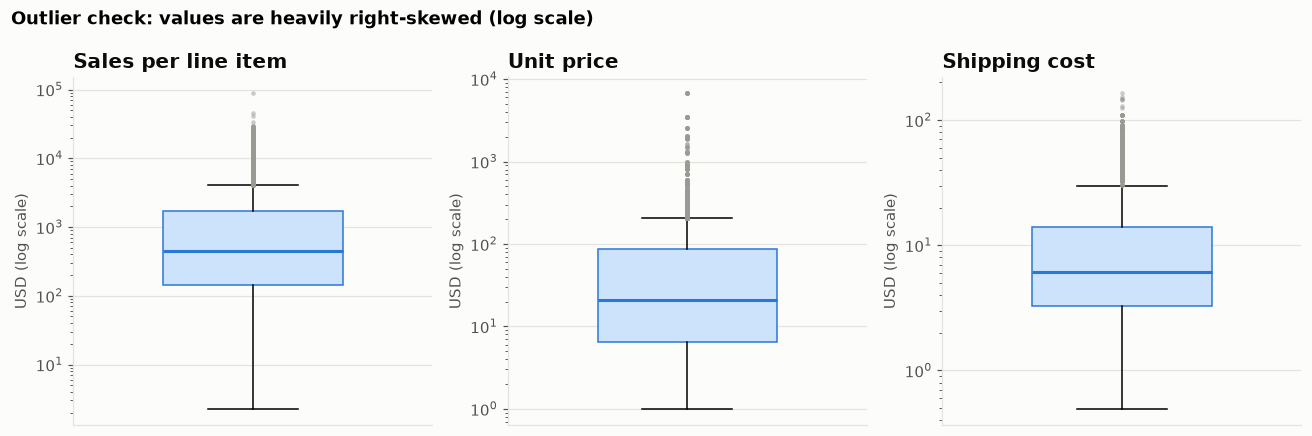

In [14]:
# Visual check: box plots on a log scale (sales spans from a few dollars to ~$89K)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col, title in zip(axes, ["sales", "unit_price", "shipping_cost"],
                          ["Sales per line item", "Unit price", "Shipping cost"]):
    ax.boxplot(df[col], vert=True, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=vs.BLUE),
               medianprops=dict(color=vs.BLUE, linewidth=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=vs.GRAY,
                               markeredgecolor="none", alpha=0.5))
    ax.set_yscale("log"); ax.set_title(title); ax.set_xticks([])
    ax.set_ylabel("USD (log scale)")
fig.suptitle("Outlier check: values are heavily right-skewed (log scale)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
vs.save(fig, "01_outlier_boxplots.png"); plt.show()

## Step 9 · Create calculated columns

| New column | Formula | Why it is useful |
|---|---|---|
| `gross_sales` | quantity × unit_price | List-price value of the line before discounts and adjustments |
| `discount_pct` | discount × 100 | Discount as a readable percentage |
| `discount_amount` | gross_sales × discount | Estimated money given away as discount |
| `profit_margin_pct` | profit ÷ sales × 100 | How much of each sales dollar is kept as profit |
| `order_year`, `order_quarter`, `order_month`, `month_name`, `year_month` | from order_date | Time-based analysis |
| `ship_days` | ship_date − order_date | Delivery speed |
| `profit_status` | Profit / Loss | Quick filter for loss-making lines |
| `discount_band` | grouped discount | Compare profitability across discount levels |
| `price_band` | grouped unit price | Low / mid / premium product analysis |

**Important: which column is "revenue"?** The original `sales` column is the revenue
recorded for each line. It does **not** exactly equal quantity × unit price, because the
data provider applied discounts and other adjustments before recording it. We therefore use
the **original `sales` column for all revenue figures**. The derived `gross_sales`
(quantity × unit price) is provided for comparison, as the project brief requires.

In [15]:
df["gross_sales"] = (df["quantity"] * df["unit_price"]).round(2)
df["discount_pct"] = (df["discount"] * 100).round(1)
df["discount_amount"] = (df["gross_sales"] * df["discount"]).round(2)
df["profit_margin_pct"] = (df["profit"] / df["sales"] * 100).round(2)

df["order_year"] = df["order_date"].dt.year
df["order_quarter"] = "Q" + df["order_date"].dt.quarter.astype(str)
df["order_month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.strftime("%b")
df["year_month"] = df["order_date"].dt.to_period("M").astype(str)

df["profit_status"] = np.where(df["profit"] >= 0, "Profit", "Loss")
df["discount_band"] = pd.cut(df["discount"], bins=[-0.001, 0.02, 0.05, 0.08, 1.0],
                             labels=["0-2%", "3-5%", "6-8%", "9%+"])
df["price_band"] = pd.cut(df["unit_price"], bins=[0, 20, 100, 500, np.inf],
                          labels=["Budget (<$20)", "Mid ($20-100)", "Upper ($100-500)",
                                  "Premium ($500+)"])

ratio = df["sales"] / df["gross_sales"]
print(f"Recorded sales ÷ (quantity × unit price): median {ratio.median():.3f}, "
      f"IQR {ratio.quantile(.25):.3f}-{ratio.quantile(.75):.3f}")
log("Derived columns", "Created gross_sales, discount_pct, discount_amount, profit_margin_pct, "
    "order_year, order_quarter, order_month, month_name, year_month, ship_days, profit_status, "
    "discount_band, price_band. Revenue analysis uses the original sales column "
    f"(median sales/gross_sales ratio = {ratio.median():.3f}).")
df[["quantity", "unit_price", "gross_sales", "sales", "discount_pct",
    "profit", "profit_margin_pct", "year_month", "profit_status"]].head()

Recorded sales ÷ (quantity × unit price): median 1.004, IQR 0.961-1.049
[Derived columns] Created gross_sales, discount_pct, discount_amount, profit_margin_pct, order_year, order_quarter, order_month, month_name, year_month, ship_days, profit_status, discount_band, price_band. Revenue analysis uses the original sales column (median sales/gross_sales ratio = 1.004).


,quantity,unit_price,gross_sales,sales,discount_pct,profit,profit_margin_pct,year_month,profit_status
0,6,38.94,233.64,261.5400,4.0,-213.25,-81.54,2010-10,Loss
1,49,208.16,10199.84,10123.0200,7.0,457.81,4.52,2012-10,Profit
2,27,8.69,234.63,244.5700,1.0,46.71,19.10,2012-10,Profit
3,30,195.99,5879.70,4965.7595,8.0,1198.97,24.14,2011-07,Profit
4,19,21.78,413.82,394.2700,8.0,30.94,7.85,2010-08,Profit


## Step 10 · Final check and save

In [16]:
col_order = ["row_id", "order_id", "order_date", "ship_date", "ship_days", "order_year",
             "order_quarter", "order_month", "month_name", "year_month", "order_priority",
             "ship_mode", "customer_name", "segment", "province", "region", "category",
             "sub_category", "product_name", "product_container", "product_base_margin",
             "base_margin_imputed", "unit_price", "quantity", "gross_sales", "discount",
             "discount_pct", "discount_band", "discount_amount", "sales", "shipping_cost",
             "profit", "profit_margin_pct", "profit_status", "price_band",
             "is_sales_outlier", "is_profit_outlier", "is_ship_delay_anomaly"]
df = df[col_order].sort_values(["order_date", "order_id", "row_id"]).reset_index(drop=True)

assert df.isna().sum().sum() == 0, "There should be no missing values"
assert df["row_id"].is_unique, "row_id must be unique"
assert len(df) == 8399

df.to_csv(CLEAN_PATH, index=False, date_format="%Y-%m-%d")
log("Save", f"Saved cleaned dataset: {df.shape[0]} rows x {df.shape[1]} columns -> "
    "dataset/cleaned_data.csv", None, len(df))

summary = {
    "raw_rows": int(raw.shape[0]), "raw_columns": int(raw.shape[1]),
    "clean_rows": int(df.shape[0]), "clean_columns": int(df.shape[1]),
    "date_min": str(df["order_date"].min().date()), "date_max": str(df["order_date"].max().date()),
    "n_orders": int(df["order_id"].nunique()), "n_customers": int(df["customer_name"].nunique()),
    "n_products": int(df["product_name"].nunique()),
    "n_categories": int(df["category"].nunique()), "n_sub_categories": int(df["sub_category"].nunique()),
    "n_provinces": int(df["province"].nunique()), "n_regions": int(df["region"].nunique()),
    "base_margin_imputed": n_imputed, "spelling_fixes": n_fixed,
    "neg_profit_share_pct": round(neg_share, 1),
    "multi_customer_orders": multi_cust_orders, "multi_province_customers": multi_prov_cust,
    "sales_outliers": int(df["is_sales_outlier"].sum()),
    "sales_outlier_revenue_share_pct": round(share_rev_outliers, 1),
    "ship_delay_anomalies": int(df["is_ship_delay_anomaly"].sum()),
    "sales_to_gross_median_ratio": round(float(ratio.median()), 3),
    "validation": validation.to_dict("records"),
    "outliers": outlier_summary.to_dict("records"),
    "log": cleaning_log,
}
with open("../results/cleaning_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
pd.DataFrame(cleaning_log).to_csv("../results/cleaning_log.csv", index=False)
print("Cleaning log saved to results/cleaning_log.csv")
df.info()

[Save] Saved cleaned dataset: 8399 rows x 38 columns -> dataset/cleaned_data.csv
Cleaning log saved to results/cleaning_log.csv
<class 'pandas.DataFrame'>
RangeIndex: 8399 entries, 0 to 8398
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   row_id                 8399 non-null   int64         
 1   order_id               8399 non-null   int64         
 2   order_date             8399 non-null   datetime64[us]
 3   ship_date              8399 non-null   datetime64[us]
 4   ship_days              8399 non-null   int64         
 5   order_year             8399 non-null   int32         
 6   order_quarter          8399 non-null   str           
 7   order_month            8399 non-null   int32         
 8   month_name             8399 non-null   str           
 9   year_month             8399 non-null   str           
 10  order_priority         8399 non-null   category      
 11  ship

## Summary
* The raw file was read with its true encoding (Mac Roman) and line endings, so no rows or
  symbols were lost.
* One empty row was removed. No duplicate transactions were found.
* Two location spellings were corrected. Missing product base margins were imputed and flagged.
* Every business-rule validation was checked and its result recorded.
* Outliers were **kept and flagged**, not deleted, because large orders are genuine revenue.
* Calculated columns for revenue, margin, discount and time were added.

Next: **02_exploratory_analysis.ipynb**